# 🌍 Indic Climate Stance Detection: SLM Training Notebook
### Train, Evaluate & Visualize a Compact Multilingual Small Language Model (SLM) for Hindi & Bengali

**Target Claim**: *"Climate change and global warming is a serious concern."*  
**Stance Classes**:
- **`FAVOUR`**: The text agrees with, supports, or expresses concern about climate change.
- **`AGAINST`**: The text dismisses, opposes, denies, or rejects climate change concern.
- **`NONE`**: The text is neutral, factual, ambiguous, or lacks an explicit stance.

---
### 💡 What this notebook does:
1. Loads the **preprocessed, leakage-free Indic Climate Stance Dataset** (Hindi, Bengali, Hinglish, Banglish).
2. Builds a **compact 4-layer Student SLM** based on `google/muril-base-cased` with **LoRA (Low-Rank Adaptation)** (~100k trainable parameters).
3. Executes a **live interactive training loop** with per-epoch loss, validation accuracy, and Macro-F1 tracking.
4. Plots **Training Loss** and **Macro-F1** learning curves side-by-side.
5. Evaluates on the held-out test split with a **Confusion Matrix Heatmap** and **per-language breakdown** (Hindi vs. Bengali).
6. Provides an **Interactive Stance Prediction Sandbox** where you can type any text and see the live prediction, confidence bar chart, and language/script analysis.

In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install peft

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 38.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [peft]1/2 [peft]
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 524.6 kB/s  0:00:24m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 295.7 kB/s  0:00:02eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 530.1 kB/s  0:00:08m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 896.5 kB/s  0:00:04 eta 0:00:01
  Attempting uninstall: safetensors
    Found existing installation: safetensors 0.7.0
    Uninstalling safetensors-0.7.0:
      Successfully uninstalled safetensors-0.7.0
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
  Attempting uninstall: hf-xet
    Found existing installation: hf-xet 1.4.3
    Uninstalling hf-xet-1.4.3:
      Successfully uninstalled hf-xet-1.4.3
  Attempting uninstall: click╺━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/10 [hf-xet]
    Found existing installation: click 8.3.2━━━━━━━━━━━━━━━━━━  3/10 [hf-xet]
    Uninstalling click-8.3.2:

In [2]:
%pip install -U ipywidgets jupyter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 27.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [jupyter]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import sys
import json
import time
from pathlib import Path

# Automatically detect project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, AutoModel
from peft import LoraConfig, get_peft_model
from src.models.classification_head import StanceHead

# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Hardware detection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Execution Device: {device.type.upper()}")
if device.type == "cuda":
    print(f"   GPU: {torch.cuda.get_device_name(0)}")
else:
    torch.set_num_threads(os.cpu_count() or 4)
    print(f"   CPU Threads: {torch.get_num_threads()}")

🚀 Execution Device: CUDA
   GPU: NVIDIA H200


## 1. Load Preprocessed Indic Climate Dataset
We load the pre-computed, group-stratified splits from `data/splits/indic_climate_splits.json`.
Group stratification guarantees **zero text leakage** across the splits even if duplicates exist in raw data.

📊 Dataset Summary:
   • Train Split:       1051 samples
   • Validation Split:   214 samples
   • Test Split:         235 samples
   • Total Records:     1500 samples

🔍 Sample Training Records:
   [AGAINST] (Bengali | Latin     ) Dada shunun, Global warming kono serious issue na, shob funding pabar natok.
   [NONE   ] (Hindi   | Latin     ) Honestly speaking Met department ne kal light rainfall predict kiya hai.
   [AGAINST] (Hindi   | Devanagari) सब दिखावा है, यह कोई गंभीर संकट नहीं है, प्रकृति खुद अपना संतुलन बना लेती है। कोई संकट नहीं है।
   [AGAINST] (Hindi   | Devanagari) कुछ भी बोलते हैं, जलवायु परिवर्तन का कोई ठोस सबूत नहीं है, सिर्फ फर्जी कंप्यूटर मॉडल बनाए जाते हैं। सब फर्जी बातें हैं।


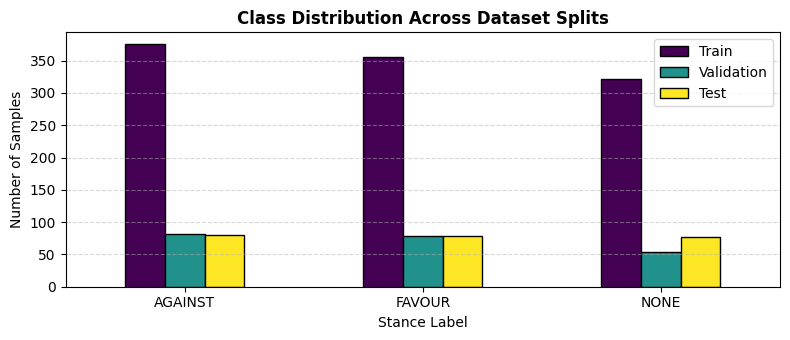

In [2]:
splits_path = ROOT / "data" / "splits" / "indic_climate_splits.json"
assert splits_path.exists(), f"Splits file not found at {splits_path}"

with open(splits_path, encoding="utf-8") as f:
    splits_data = json.load(f)

train_recs = splits_data["splits"]["train"]
val_recs = splits_data["splits"]["val"]
test_recs = splits_data["splits"]["test"]

print("📊 Dataset Summary:")
print(f"   • Train Split:      {len(train_recs):>5} samples")
print(f"   • Validation Split: {len(val_recs):>5} samples")
print(f"   • Test Split:       {len(test_recs):>5} samples")
print(f"   • Total Records:    {len(train_recs) + len(val_recs) + len(test_recs):>5} samples")

# Display sample records from the dataset
print("\n🔍 Sample Training Records:")
df_train = pd.DataFrame(train_recs)
for _, row in df_train.sample(4, random_state=42).iterrows():
    lang = row.get("language", "Unknown")
    script = row.get("script", "Unknown")
    print(f"   [{row['label']:<7}] ({lang:<7} | {script:<10}) {row['text']}")

# Plot class distribution across splits
fig, ax = plt.subplots(figsize=(8, 3.5))
dist_df = pd.DataFrame({
    'Train': pd.Series([r['label'] for r in train_recs]).value_counts(),
    'Validation': pd.Series([r['label'] for r in val_recs]).value_counts(),
    'Test': pd.Series([r['label'] for r in test_recs]).value_counts()
}).fillna(0)
dist_df.plot(kind='bar', ax=ax, colormap='viridis', edgecolor='black')
plt.title("Class Distribution Across Dataset Splits", fontsize=12, fontweight='bold')
plt.xlabel("Stance Label")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 2. Model Architecture: Compact Student SLM with LoRA
We instantiate a compact Small Language Model (SLM) derived from `google/muril-base-cased`:
1. **Depth Pruning**: We keep the first **4 transformer layers** (out of 12).
2. **LoRA Adapters**: We freeze the 180M backbone weights and only train rank-8 attention adapter projections ($W_q, W_v$) + the stance classification head.
3. **Trainable Footprint**: Only **~100k parameters** (0.06% of the model), enabling fast training on CPU or GPU without RAM bottlenecks.

In [3]:
ENCODER_NAME = "google/muril-base-cased"
LABELS = ["FAVOUR", "AGAINST", "NONE"]
L2I = {l: i for i, l in enumerate(LABELS)}
I2L = {i: l for l, i in L2I.items()}

print(f"Loading tokenizer: {ENCODER_NAME}...")
tokenizer = AutoTokenizer.from_pretrained(ENCODER_NAME)

class CompactStudentSLM(torch.nn.Module):
    def __init__(self, encoder_name=ENCODER_NAME, keep_layers=4, r=8, dropout=0.1):
        super().__init__()
        self.encoder_name = encoder_name
        self.encoder = AutoModel.from_pretrained(encoder_name, use_safetensors=True)
        
        # 1. Depth-prune transformer layers to 4 layers
        if keep_layers < len(self.encoder.encoder.layer):
            self.encoder.encoder.layer = torch.nn.ModuleList(list(self.encoder.encoder.layer)[:keep_layers])
            
        # 2. Freeze base encoder parameters
        for p in self.encoder.parameters():
            p.requires_grad = False
            
        # 3. Inject LoRA adapters (r=8, alpha=16) on query and value projections
        lora_cfg = LoraConfig(
            r=r, 
            lora_alpha=2 * r, 
            lora_dropout=0.05, 
            bias="none",
            target_modules=["query", "value"]
        )
        self.encoder = get_peft_model(self.encoder, lora_cfg)
        
        # 4. Multilingual Stance Head with Mean Pooling
        self.head = StanceHead(self.encoder.config.hidden_size, num_labels=3, dropout=dropout, pooling="mean")
        
    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        return self.head(out, attention_mask)
        
    def count_parameters(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return total, trainable

student_model = CompactStudentSLM(ENCODER_NAME, keep_layers=4, r=8).to(device)
total_params, trainable_params = student_model.count_parameters()

print(f"\n✅ Compact Student SLM Initialized:")
print(f"   • Total Parameters:     {total_params:>12,}")
print(f"   • Trainable Parameters: {trainable_params:>12,} ({trainable_params / total_params * 100:.2f}% of total)")
print(f"   • Frozen Base Weights:  {total_params - trainable_params:>12,}")

Loading tokenizer: google/muril-base-cased...


config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



✅ Compact Student SLM Initialized:
   • Total Parameters:      180,953,859
   • Trainable Parameters:      100,611 (0.06% of total)
   • Frozen Base Weights:   180,853,248


## 3. Dataset Tokenization & PyTorch DataLoaders
Tokenizes text inputs with max length 64 and packages them into batched PyTorch DataLoaders.

In [4]:
class IndicStanceDataset(Dataset):
    def __init__(self, records, tok, max_length=64):
        self.records = records
        self.tok = tok
        self.max_length = max_length
        
    def __len__(self):
        return len(self.records)
        
    def __getitem__(self, idx):
        item = self.records[idx]
        enc = self.tok(
            str(item["text"]),
            truncation=True,
            max_length=self.max_length,
            padding="max_length",
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "label": torch.tensor(L2I[str(item["label"])], dtype=torch.long)
        }

BATCH_SIZE = 8
train_loader = DataLoader(IndicStanceDataset(train_recs, tokenizer), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(IndicStanceDataset(val_recs, tokenizer), batch_size=BATCH_SIZE * 2, shuffle=False)
test_loader = DataLoader(IndicStanceDataset(test_recs, tokenizer), batch_size=BATCH_SIZE * 2, shuffle=False)

print(f"DataLoaders prepared (batch_size={BATCH_SIZE}):")
print(f"   • Train: {len(train_loader)} batches | Val: {len(val_loader)} batches | Test: {len(test_loader)} batches")

DataLoaders prepared (batch_size=8):
   • Train: 132 batches | Val: 14 batches | Test: 15 batches


## 4. Execute Model Training
Run the training loop directly in this cell. You will see:
- Live step/epoch loss
- Validation Macro-F1 after every epoch
- Automatic checkpoint tracking for the best model

In [5]:
from sklearn.metrics import f1_score, accuracy_score
from collections import Counter

# --- Hyperparameters ---
EPOCHS = 4             # Adjust number of epochs (recommended: 4 to 6)
LR = 3e-4              # Learning rate for LoRA adapters
GRAD_ACCUM = 2         # Gradient accumulation steps

# Inverse-frequency class weights to balance minority classes
class_counts = Counter([r["label"] for r in train_recs])
weights = torch.tensor([1.0 / max(1, class_counts[lbl]) for lbl in LABELS], dtype=torch.float).to(device)
weights = weights / weights.sum() * 3.0
criterion = torch.nn.CrossEntropyLoss(weight=weights)

# Optimizer
optimizer = torch.optim.AdamW(
    [p for p in student_model.parameters() if p.requires_grad],
    lr=LR,
    weight_decay=0.01
)

history = {"train_loss": [], "val_loss": [], "val_macro_f1": [], "val_acc": []}
best_f1 = -1.0
best_state = None
t_start = time.time()

print("=" * 66)
print(f"{'Epoch':^7} | {'Train Loss':^12} | {'Val Loss':^10} | {'Val Macro-F1':^14} | {'Val Acc':^9}")
print("=" * 66)

for epoch in range(1, EPOCHS + 1):
    student_model.train()
    running_loss = 0.0
    optimizer.zero_grad()
    
    for i, batch in enumerate(train_loader):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)
        
        logits = student_model(input_ids, attention_mask)
        loss = criterion(logits, labels) / GRAD_ACCUM
        loss.backward()
        running_loss += loss.item() * GRAD_ACCUM
        
        if (i + 1) % GRAD_ACCUM == 0 or (i + 1) == len(train_loader):
            torch.nn.utils.clip_grad_norm_(student_model.parameters(), 1.0)
            optimizer.step()
            optimizer.zero_grad()
            
    epoch_train_loss = running_loss / len(train_loader)
    
    # Evaluate on Validation split
    student_model.eval()
    val_loss = 0.0
    val_preds, val_golds = [], []
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            
            logits = student_model(input_ids, attention_mask)
            v_loss = criterion(logits, labels)
            val_loss += v_loss.item()
            
            preds = logits.argmax(dim=-1).cpu().tolist()
            val_preds.extend(preds)
            val_golds.extend(labels.cpu().tolist())
            
    epoch_val_loss = val_loss / len(val_loader)
    val_f1 = f1_score(val_golds, val_preds, average="macro", zero_division=0)
    val_acc = accuracy_score(val_golds, val_preds)
    
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["val_macro_f1"].append(val_f1)
    history["val_acc"].append(val_acc)
    
    star = " 🌟 (best)" if val_f1 > best_f1 else ""
    print(f" {epoch:^5} | {epoch_train_loss:^12.4f} | {epoch_val_loss:^10.4f} | {val_f1:^14.4f} | {val_acc:^9.4f}{star}")
    
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_state = {k: v.detach().clone().cpu() for k, v in student_model.state_dict().items()}

wall_time = time.time() - t_start
print("=" * 66)
print(f"🎉 Training Complete in {wall_time:.1f}s | Best Validation Macro-F1: {best_f1:.4f}")

# Restore best checkpoint
if best_state is not None:
    student_model.load_state_dict(best_state)

 Epoch  |  Train Loss  |  Val Loss  |  Val Macro-F1  |  Val Acc 
   1   |    1.0082    |   0.7853   |     0.8855     |  0.8785   🌟 (best)
   2   |    0.3415    |   0.1558   |     0.9574     |  0.9533   🌟 (best)
   3   |    0.0698    |   0.0605   |     0.9865     |  0.9860   🌟 (best)
   4   |    0.0317    |   0.0606   |     0.9865     |  0.9860  
🎉 Training Complete in 5.5s | Best Validation Macro-F1: 0.9865


## 5. Training & Validation Curves
Plots Loss and Macro-F1 curves to inspect convergence and ensure there is no overfitting.

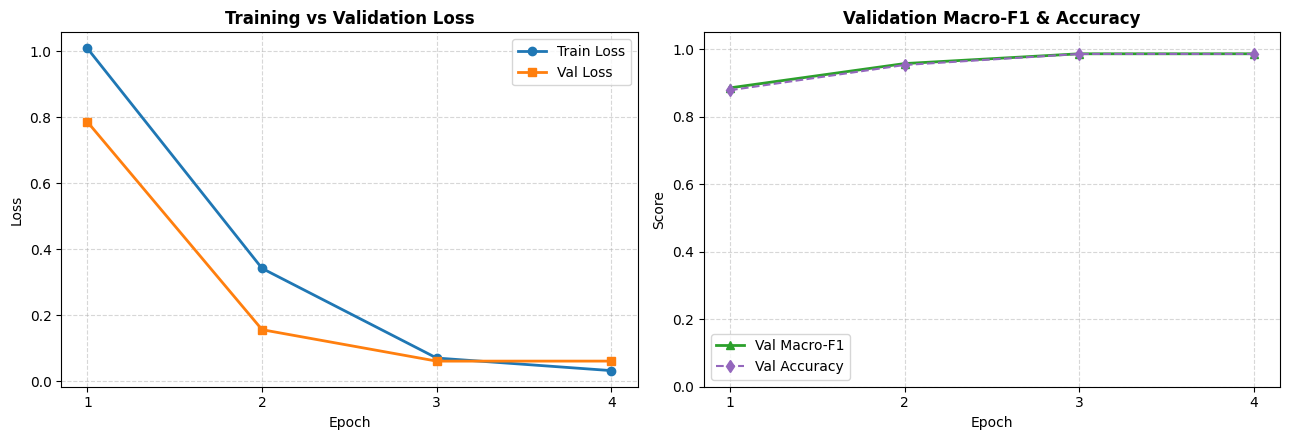

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
epochs_range = range(1, len(history["train_loss"]) + 1)

# Loss Plot
ax1.plot(epochs_range, history["train_loss"], marker='o', label="Train Loss", color="#1f77b4", linewidth=2)
ax1.plot(epochs_range, history["val_loss"], marker='s', label="Val Loss", color="#ff7f0e", linewidth=2)
ax1.set_title("Training vs Validation Loss", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_xticks(epochs_range)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# Macro-F1 Plot
ax2.plot(epochs_range, history["val_macro_f1"], marker='^', label="Val Macro-F1", color="#2ca02c", linewidth=2)
ax2.plot(epochs_range, history["val_acc"], marker='d', label="Val Accuracy", color="#9467bd", linestyle="--", linewidth=1.5)
ax2.set_title("Validation Macro-F1 & Accuracy", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Score")
ax2.set_xticks(epochs_range)
ax2.set_ylim([0.0, 1.05])
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

## 6. Comprehensive Test Set Evaluation
Evaluates the best checkpoint on the held-out test split (235 items) and calculates:
- Overall **Macro-F1**, **Accuracy**, and **Weighted-F1**
- Per-class precision, recall, and F1 scores
- Per-language breakdown (Hindi vs Bengali)
- Confusion Matrix Heatmap

🏆 Final Test Set Results (n=235):
   • Macro-F1:          0.9574
   • Accuracy:          0.9574
   • Weighted-F1:       0.9571
   • Cohen's Kappa:     0.9362

🌐 Per-Language Breakdown:
   • Bengali    Macro-F1: 0.9354 | Accuracy: 0.9381 (n=113)
   • Hindi      Macro-F1: 0.9762 | Accuracy: 0.9754 (n=122)

📋 Detailed Classification Report:
              precision    recall  f1-score   support

      FAVOUR     0.9863    0.9000    0.9412        80
     AGAINST     0.9268    0.9744    0.9500        78
        NONE     0.9625    1.0000    0.9809        77

    accuracy                         0.9574       235
   macro avg     0.9585    0.9581    0.9574       235
weighted avg     0.9588    0.9574    0.9571       235



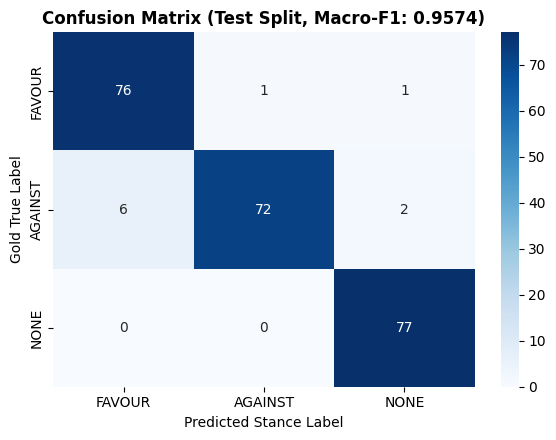

In [7]:
from sklearn.metrics import classification_report, confusion_matrix
from src.evaluation.metrics import compute_metrics, per_language_report

student_model.eval()
test_preds, test_golds, test_probs = [], [], []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)
        
        logits = student_model(input_ids, attention_mask)
        probs = torch.softmax(logits, dim=-1)
        
        test_probs.extend(probs.cpu().tolist())
        test_preds.extend(logits.argmax(dim=-1).cpu().tolist())
        test_golds.extend(labels.cpu().tolist())

gold_labels = [I2L[i] for i in test_golds]
pred_labels = [I2L[i] for i in test_preds]

# 1. Primary Metrics
metrics = compute_metrics(gold_labels, pred_labels)
print(f"🏆 Final Test Set Results (n={metrics['n']}):")
print(f"   • Macro-F1:          {metrics['macro_f1']:.4f}")
print(f"   • Accuracy:          {metrics['accuracy']:.4f}")
print(f"   • Weighted-F1:       {metrics['weighted_f1']:.4f}")
print(f"   • Cohen's Kappa:     {metrics['cohen_kappa']:.4f}")

# 2. Per-Language Breakdown
lang_rep = per_language_report(test_recs, gold_labels, pred_labels)
print("\n🌐 Per-Language Breakdown:")
for lang, m in lang_rep.items():
    print(f"   • {lang:<10} Macro-F1: {m['macro_f1']:.4f} | Accuracy: {m['accuracy']:.4f} (n={m['n']})")

# 3. Detailed Class Report
print("\n📋 Detailed Classification Report:")
print(classification_report(gold_labels, pred_labels, target_names=LABELS, digits=4))

# 4. Confusion Matrix Heatmap
cm = confusion_matrix(gold_labels, pred_labels, labels=LABELS)
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS, ax=ax)
plt.title(f"Confusion Matrix (Test Split, Macro-F1: {metrics['macro_f1']:.4f})", fontweight='bold')
plt.xlabel("Predicted Stance Label")
plt.ylabel("Gold True Label")
plt.tight_layout()
plt.show()

## 7. Interactive Stance Inference Sandbox 🌍
Test the trained model interactively on custom Hindi, Bengali, Hinglish, Banglish, or English sentences.

Input:       "जलवायु परिवर्तन हमारे अस्तित्व के लिए सबसे गंभीर खतरा है।"
Prediction:  🟢 FAVOUR (Confidence: 99.3%)
Language:    Hindi | Script: Devanagari
Probabilities: FAVOUR: 0.9926 | AGAINST: 0.0034 | NONE: 0.0039


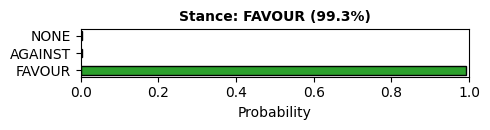

Input:       "ग्लोबल वार्मिंग कोई गंभीर समस्या नहीं है, यह सिर्फ पश्चिमी देशों का प्रोपेगैंडा है।"
Prediction:  🔴 AGAINST (Confidence: 89.8%)
Language:    Hindi | Script: Devanagari
Probabilities: FAVOUR: 0.1007 | AGAINST: 0.8978 | NONE: 0.0015


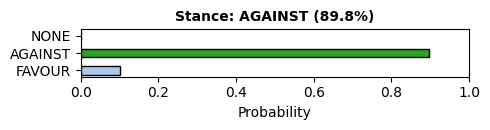

Input:       "জলবায়ু পরিবর্তন একটি বাস্তব সংকট, এখনই কার্বন নির্গমন কমাতে হবে।"
Prediction:  🟢 FAVOUR (Confidence: 99.4%)
Language:    Bengali | Script: Bengali
Probabilities: FAVOUR: 0.9939 | AGAINST: 0.0042 | NONE: 0.0019


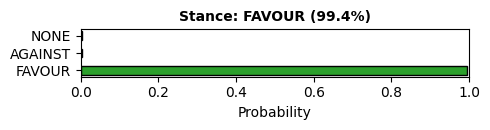

Input:       "গ্লোবাল ওয়ার্মিং কোনো গুরুতর समस्या নয়, এটি একটি সাজানো নাটক।"
Prediction:  🔴 AGAINST (Confidence: 95.7%)
Language:    Bengali | Script: Bengali
Probabilities: FAVOUR: 0.0367 | AGAINST: 0.9569 | NONE: 0.0063


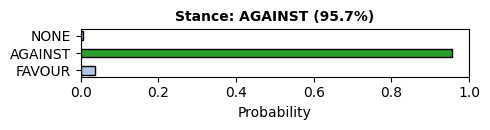

Input:       "Climate change sach me ek bahut serious concern hai bhai."
Prediction:  🟢 FAVOUR (Confidence: 99.0%)
Language:    Hindi | Script: Latin
Probabilities: FAVOUR: 0.9897 | AGAINST: 0.0068 | NONE: 0.0035


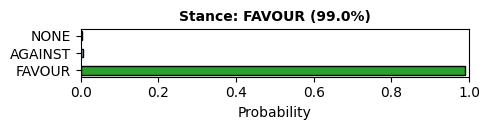

Input:       "सौर ऊर्जा लगाने में कितना खर्च आता है, कोई जानकारी दे सकता है?"
Prediction:  ⚪ NONE (Confidence: 99.5%)
Language:    Hindi | Script: Devanagari
Probabilities: FAVOUR: 0.0027 | AGAINST: 0.0025 | NONE: 0.9948


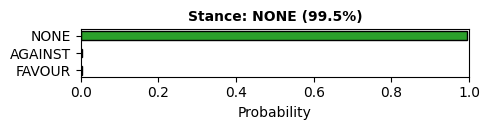

In [8]:
from src.data.preprocessing import preprocess
from src.data.language_detection import detect_language, detect_script

def predict_stance_interactive(text: str):
    clean = preprocess(text, variant="minimal").text
    enc = tokenizer(clean, truncation=True, max_length=64, return_tensors="pt")
    
    student_model.eval()
    with torch.no_grad():
        logits = student_model(enc["input_ids"].to(device), enc["attention_mask"].to(device))
        probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()
        pred_idx = int(probs.argmax())
        
    pred_label = I2L[pred_idx]
    conf = float(probs[pred_idx])
    lang = detect_language(text)
    script = detect_script(text)
    
    badges = {"FAVOUR": "🟢 FAVOUR", "AGAINST": "🔴 AGAINST", "NONE": "⚪ NONE"}
    print("=" * 60)
    print(f'Input:       "{text}"')
    print(f"Prediction:  {badges.get(pred_label, pred_label)} (Confidence: {conf * 100:.1f}%)")
    print(f"Language:    {lang} | Script: {script}")
    print(f"Probabilities: FAVOUR: {probs[0]:.4f} | AGAINST: {probs[1]:.4f} | NONE: {probs[2]:.4f}")
    
    fig, ax = plt.subplots(figsize=(5, 1.4))
    bar_colors = ["#2ca02c" if l == pred_label else "#aec7e8" for l in LABELS]
    ax.barh(LABELS, probs, color=bar_colors, edgecolor='black', height=0.5)
    ax.set_xlim([0, 1.0])
    ax.set_xlabel("Probability")
    plt.title(f"Stance: {pred_label} ({conf * 100:.1f}%)", fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.show()

# Test benchmark examples
samples = [
    "जलवायु परिवर्तन हमारे अस्तित्व के लिए सबसे गंभीर खतरा है।",
    "ग्लोबल वार्मिंग कोई गंभीर समस्या नहीं है, यह सिर्फ पश्चिमी देशों का प्रोपेगैंडा है।",
    "জলবায়ু পরিবর্তন একটি বাস্তব সংকট, এখনই কার্বন নির্গমন কমাতে হবে।",
    "গ্লোবাল ওয়ার্মিং কোনো গুরুতর समस्या নয়, এটি একটি সাজানো নাটক।",
    "Climate change sach me ek bahut serious concern hai bhai.",
    "सौर ऊर्जा लगाने में कितना खर्च आता है, कोई जानकारी दे सकता है?",
]

for s in samples:
    predict_stance_interactive(s)

### ✍️ Test Your Own Statement
Change `my_text` below and run the cell to classify any statement:

Input:       "ग्लोबल वार्मिंग कोई समस्या नहीं है"
Prediction:  🟢 FAVOUR (Confidence: 94.0%)
Language:    Hindi | Script: Devanagari
Probabilities: FAVOUR: 0.9401 | AGAINST: 0.0527 | NONE: 0.0072


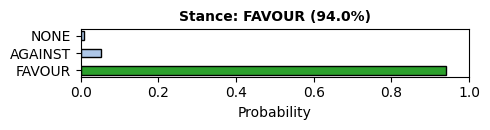

In [9]:
# 👉 Enter any sentence here:
my_text = "ग्लोबल वार्मिंग कोई समस्या नहीं है"

predict_stance_interactive(my_text)

## 8. Export Trained LoRA Checkpoint
Saves your trained weights to `models/student/lora_adapter_kd.pt` so other project modules (Streamlit app, CLI, API) immediately use your trained model.

In [10]:
save_dir = ROOT / "models" / "student"
save_dir.mkdir(parents=True, exist_ok=True)
adapter_path = save_dir / "lora_adapter_kd.pt"

# Extract adapter and classification head weights
adapter_state = {
    k: v.detach().clone().cpu() for k, v in student_model.state_dict().items() 
    if ("lora" in k) or k.startswith("head.")
}

torch.save(adapter_state, adapter_path)
print(f"💾 Trained adapter saved successfully to:")
print(f"   {adapter_path}")
print(f"   Size: {adapter_path.stat().st_size / 1024:.1f} KB ({len(adapter_state)} weight tensors)")

💾 Trained adapter saved successfully to:
   /workspace/indic-climate-stance-slm/models/student/lora_adapter_kd.pt
   Size: 400.2 KB (18 weight tensors)


In [11]:
# Display all DataFrames currently loaded in your notebook

import pandas as pd

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\nDataset: {name}")
        print("Shape:", obj.shape)
        print("Columns:", list(obj.columns))
        print(obj.head(2))


Dataset: df_train
Shape: (1051, 9)
Columns: ['id', 'text', 'language', 'script', 'label', 'linguistic_feature', 'annotation_status', 'source', 'confidence']
            id                                               text language  \
0  indic_00001  जलवायु परिवर्तन हमारे अस्तित्व के लिए सबसे गंभ...    Hindi   
1  indic_00003  इस साल की भीषण गर्मी और सूखा साफ दिखाता है कि ...    Hindi   

       script   label linguistic_feature annotation_status  \
0  Devanagari  FAVOUR      favour_native    human_verified   
1  Devanagari  FAVOUR      favour_native    human_verified   

                        source  confidence  
0  indic_climate_social_corpus         1.0  
1  indic_climate_social_corpus         1.0  

Dataset: dist_df
Shape: (3, 3)
Columns: ['Train', 'Validation', 'Test']
         Train  Validation  Test
AGAINST    375          82    80
FAVOUR     355          79    78


In [13]:
# TEST 1: DATA LEAKAGE AUDIT

import pandas as pd
from collections import Counter

def normalize_text(text):
    return " ".join(str(text).strip().lower().split())

train_texts = [normalize_text(r["text"]) for r in train_recs]
val_texts = [normalize_text(r["text"]) for r in val_recs]
test_texts = [normalize_text(r["text"]) for r in test_recs]

train_set = set(train_texts)
val_set = set(val_texts)
test_set = set(test_texts)

print("=" * 55)
print("DATA LEAKAGE AUDIT")
print("=" * 55)

print("Train samples:", len(train_texts))
print("Validation samples:", len(val_texts))
print("Test samples:", len(test_texts))

print("\nExact text overlap:")

print("Train ↔ Validation:", len(train_set & val_set))
print("Train ↔ Test:", len(train_set & test_set))
print("Validation ↔ Test:", len(val_set & test_set))

print("\nDuplicate samples within splits:")

print("Train:", len(train_texts) - len(train_set))
print("Validation:", len(val_texts) - len(val_set))
print("Test:", len(test_texts) - len(test_set))

DATA LEAKAGE AUDIT
Train samples: 1051
Validation samples: 214
Test samples: 235

Exact text overlap:
Train ↔ Validation: 0
Train ↔ Test: 0
Validation ↔ Test: 0

Duplicate samples within splits:
Train: 395
Validation: 74
Test: 94


In [14]:
# TEST 2: CLASS DISTRIBUTION

for split_name, records in [
    ("TRAIN", train_recs),
    ("VALIDATION", val_recs),
    ("TEST", test_recs)
]:

    df = pd.DataFrame(records)

    print("\n" + "=" * 45)
    print(split_name)
    print("=" * 45)

    print("\nClass distribution:")
    print(df["label"].value_counts())

    print("\nClass percentages:")
    print((df["label"].value_counts(normalize=True) * 100).round(2))

    print("\nLanguage distribution:")
    print(df["language"].value_counts())


TRAIN

Class distribution:
label
AGAINST    375
FAVOUR     355
NONE       321
Name: count, dtype: int64

Class percentages:
label
AGAINST    35.68
FAVOUR     33.78
NONE       30.54
Name: proportion, dtype: float64

Language distribution:
language
Hindi      534
Bengali    517
Name: count, dtype: int64

VALIDATION

Class distribution:
label
AGAINST    82
FAVOUR     79
NONE       53
Name: count, dtype: int64

Class percentages:
label
AGAINST    38.32
FAVOUR     36.92
NONE       24.77
Name: proportion, dtype: float64

Language distribution:
language
Bengali    108
Hindi      106
Name: count, dtype: int64

TEST

Class distribution:
label
AGAINST    80
FAVOUR     78
NONE       77
Name: count, dtype: int64

Class percentages:
label
AGAINST    34.04
FAVOUR     33.19
NONE       32.77
Name: proportion, dtype: float64

Language distribution:
language
Hindi      122
Bengali    113
Name: count, dtype: int64


In [15]:
# TEST 3: INDEPENDENT METRIC VERIFICATION

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    cohen_kappa_score,
    classification_report
)

print("=" * 55)
print("INDEPENDENT METRIC VERIFICATION")
print("=" * 55)

print("Accuracy:",
      accuracy_score(gold_labels, pred_labels))

print("Macro-F1:",
      f1_score(gold_labels, pred_labels, average="macro"))

print("Weighted-F1:",
      f1_score(gold_labels, pred_labels, average="weighted"))

print("Macro Precision:",
      precision_score(gold_labels, pred_labels, average="macro"))

print("Macro Recall:",
      recall_score(gold_labels, pred_labels, average="macro"))

print("Cohen's Kappa:",
      cohen_kappa_score(gold_labels, pred_labels))

print("\nDetailed Classification Report:")

print(classification_report(
    gold_labels,
    pred_labels,
    labels=LABELS,
    digits=4
))

INDEPENDENT METRIC VERIFICATION
Accuracy: 0.9574468085106383
Macro-F1: 0.957356063444486
Weighted-F1: 0.9571182130529402
Macro Precision: 0.9585435460518988
Macro Recall: 0.9581196581196582
Cohen's Kappa: 0.9361915881506422

Detailed Classification Report:
              precision    recall  f1-score   support

      FAVOUR     0.9268    0.9744    0.9500        78
     AGAINST     0.9863    0.9000    0.9412        80
        NONE     0.9625    1.0000    0.9809        77

    accuracy                         0.9574       235
   macro avg     0.9585    0.9581    0.9574       235
weighted avg     0.9588    0.9574    0.9571       235



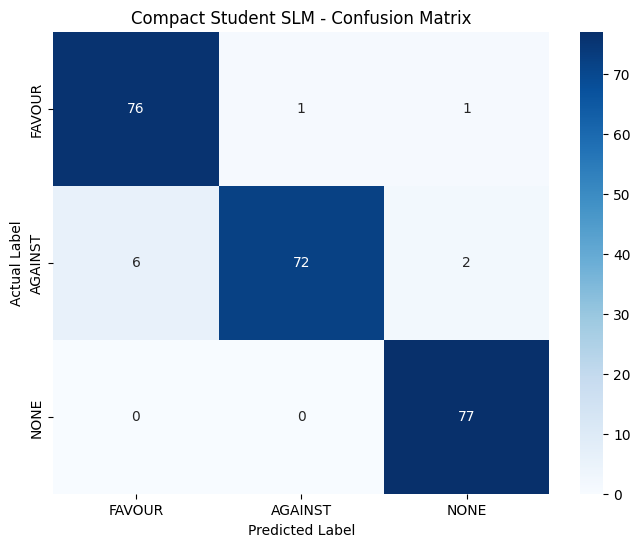


Raw Confusion Matrix:
[[76  1  1]
 [ 6 72  2]
 [ 0  0 77]]


In [17]:
# TEST 4: CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    gold_labels,
    pred_labels,
    labels=LABELS
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABELS,
    yticklabels=LABELS
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("Compact Student SLM - Confusion Matrix")

plt.show()

print("\nRaw Confusion Matrix:")
print(cm)

In [18]:
# TEST 5: PER-LANGUAGE EVALUATION

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

language_results = []

test_languages = [
    record["language"] for record in test_recs
]

for language in sorted(set(test_languages)):

    indices = [
        i for i, lang in enumerate(test_languages)
        if lang == language
    ]

    actual = [gold_labels[i] for i in indices]
    predicted = [pred_labels[i] for i in indices]

    language_results.append({

        "Language": language,

        "Samples": len(indices),

        "Accuracy": accuracy_score(
            actual, predicted
        ),

        "Macro-F1": f1_score(
            actual, predicted,
            average="macro",
            zero_division=0
        ),

        "Precision": precision_score(
            actual, predicted,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            actual, predicted,
            average="macro",
            zero_division=0
        )
    })

language_df = pd.DataFrame(language_results)

display(language_df.round(4))

,Language,Samples,Accuracy,Macro-F1,Precision,Recall
0,Bengali,113,0.9381,0.9354,0.9386,0.9417
1,Hindi,122,0.9754,0.9762,0.9752,0.9775


In [19]:
# TEST 6: PARAMETER EFFICIENCY AUDIT

total_params = sum(
    p.numel() for p in student_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in student_model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

print("=" * 55)
print("MODEL PARAMETER AUDIT")
print("=" * 55)

print(f"Total Parameters:      {total_params:,}")
print(f"Trainable Parameters:  {trainable_params:,}")
print(f"Frozen Parameters:     {frozen_params:,}")

print(
    f"Trainable Percentage: "
    f"{trainable_params / total_params * 100:.4f}%"
)

print(
    f"Frozen Percentage: "
    f"{frozen_params / total_params * 100:.4f}%"
)

MODEL PARAMETER AUDIT
Total Parameters:      180,953,859
Trainable Parameters:  100,611
Frozen Parameters:     180,853,248
Trainable Percentage: 0.0556%
Frozen Percentage: 99.9444%


In [20]:
# Inspect all trainable parameters

print("TRAINABLE LAYERS")
print("=" * 55)

for name, param in student_model.named_parameters():

    if param.requires_grad:

        print(
            f"{name:<65} "
            f"{str(tuple(param.shape)):<20} "
            f"{param.numel():,}"
        )

TRAINABLE LAYERS
encoder.base_model.model.encoder.layer.0.attention.self.query.lora_A.default.weight (8, 768)             6,144
encoder.base_model.model.encoder.layer.0.attention.self.query.lora_B.default.weight (768, 8)             6,144
encoder.base_model.model.encoder.layer.0.attention.self.value.lora_A.default.weight (8, 768)             6,144
encoder.base_model.model.encoder.layer.0.attention.self.value.lora_B.default.weight (768, 8)             6,144
encoder.base_model.model.encoder.layer.1.attention.self.query.lora_A.default.weight (8, 768)             6,144
encoder.base_model.model.encoder.layer.1.attention.self.query.lora_B.default.weight (768, 8)             6,144
encoder.base_model.model.encoder.layer.1.attention.self.value.lora_A.default.weight (8, 768)             6,144
encoder.base_model.model.encoder.layer.1.attention.self.value.lora_B.default.weight (768, 8)             6,144
encoder.base_model.model.encoder.layer.2.attention.self.query.lora_A.default.weight (8, 768)   

In [21]:
# TEST 7: INCORRECT PREDICTION ANALYSIS

errors = []

for i, (actual, predicted) in enumerate(
    zip(gold_labels, pred_labels)
):

    if actual != predicted:

        errors.append({

            "Text": test_recs[i]["text"],

            "Language": test_recs[i]["language"],

            "Actual": actual,

            "Predicted": predicted,

            "Confidence": round(
                max(test_probs[i]), 4
            )
        })

error_df = pd.DataFrame(errors)

print("Total test samples:", len(test_recs))
print("Incorrect predictions:", len(error_df))

print(
    "Error percentage:",
    round(len(error_df) / len(test_recs) * 100, 2),
    "%"
)

display(error_df)

Total test samples: 235
Incorrect predictions: 10
Error percentage: 4.26 %


,Text,Language,Actual,Predicted,Confidence
0,अगर हम अभी नहीं जागे तो आने वाले 20 सालों में ...,Hindi,FAVOUR,NONE,0.4741
1,Carbon tax lagie common man er pocket kata cha...,Bengali,AGAINST,NONE,0.6408
2,"Shiter shomoy freezing temperature hoy, kothay...",Bengali,AGAINST,FAVOUR,0.9785
3,वाह भाई! दिसंबर में 5 डिग्री तापमान है और इनको...,Hindi,AGAINST,FAVOUR,0.9868
4,इतनी भयानक धूप और लू में भी कुछ लोगों को लगता ...,Hindi,FAVOUR,AGAINST,0.6768
5,"Dada shunun, Shiter shomoy freezing temperatur...",Bengali,AGAINST,FAVOUR,0.9812
6,Actually Carbon tax lagie common man er pocket...,Bengali,AGAINST,NONE,0.6404
7,Amar mone hoy Shiter shomoy freezing temperatu...,Bengali,AGAINST,FAVOUR,0.9894
8,"Dada shunun, Shiter shomoy freezing temperatur...",Bengali,AGAINST,FAVOUR,0.9812
9,"Dada shunun, Shiter shomoy freezing temperatur...",Bengali,AGAINST,FAVOUR,0.9812


In [22]:
# TEST 8: EVALUATION ON UNIQUE TEST SAMPLES

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    cohen_kappa_score
)

# Build evaluation dataframe
audit_df = pd.DataFrame({
    "text": [r["text"] for r in test_recs],
    "language": [r["language"] for r in test_recs],
    "actual": gold_labels,
    "predicted": pred_labels
})

# Normalize text
audit_df["normalized_text"] = (
    audit_df["text"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.split()
    .str.join(" ")
)

# Find duplicate groups
duplicate_groups = (
    audit_df.groupby("normalized_text")
    .agg(
        occurrences=("actual", "size"),
        label_count=("actual", "nunique"),
        language_count=("language", "nunique"),
        actual_label=("actual", "first")
    )
    .reset_index()
)

print("TOTAL TEST RECORDS:", len(audit_df))
print("UNIQUE TEXTS:", len(duplicate_groups))

print("\nDuplicate groups:")
print(
    duplicate_groups[
        duplicate_groups["occurrences"] > 1
    ].sort_values("occurrences", ascending=False).head(20)
)

# Check conflicting labels
conflicts = duplicate_groups[
    duplicate_groups["label_count"] > 1
]

print("\nConflicting duplicate groups:", len(conflicts))

# Only evaluate unambiguous unique samples
valid_texts = set(
    duplicate_groups[
        duplicate_groups["label_count"] == 1
    ]["normalized_text"]
)

unique_df = (
    audit_df[
        audit_df["normalized_text"].isin(valid_texts)
    ]
    .drop_duplicates("normalized_text")
    .reset_index(drop=True)
)

print("\nUNIQUE SAMPLE EVALUATION")
print("=" * 45)

print("Unique samples:", len(unique_df))

print(
    "Accuracy:",
    accuracy_score(
        unique_df["actual"],
        unique_df["predicted"]
    )
)

print(
    "Macro-F1:",
    f1_score(
        unique_df["actual"],
        unique_df["predicted"],
        average="macro"
    )
)

print(
    "Weighted-F1:",
    f1_score(
        unique_df["actual"],
        unique_df["predicted"],
        average="weighted"
    )
)

print(
    "Cohen's Kappa:",
    cohen_kappa_score(
        unique_df["actual"],
        unique_df["predicted"]
    )
)

print("\nClassification Report:")

print(
    classification_report(
        unique_df["actual"],
        unique_df["predicted"],
        labels=LABELS,
        digits=4
    )
)

TOTAL TEST RECORDS: 235
UNIQUE TEXTS: 141

Duplicate groups:
                                       normalized_text  occurrences  \
127  ভাবছিলাম যে বাড়ির ছাদে সোলার প্যানেল বসাতে খর...            7   
104  একটু বলবেন কি, দার্জিলিং ভ্রমণের জন্য বছরের কো...            7   
1    actually climate change western propaganda, in...            6   
103  একটু বলবেন কি, কলকাতায় ট্রাফিকের সমস্যা দিন দ...            5   
60   नमस्ते, आज का तापमान 32 डिग्री सेल्सियस दर्ज क...            5   
102  একটু বলবেন কি, ইডেন গার্ডেন্সে রবিবারের ক্রিকে...            5   
43   कृपया बताएं, आज का तापमान 32 डिग्री सेल्सियस द...            4   
23   look at the data, har saal itni cold winter aa...            4   
45   कृपया बताएं, पेड़ लगाने के लिए नगर निगम से पौध...            4   
11   arre bhai himalayan glaciers rapid pace pe shr...            4   
13   dada shunun, dharti r temperature controll kor...            4   
88   सोच रहा था कि खेती के लिए इस बार कौन सा खाद सब...            4   
89   सोच रहा था 

In [23]:
# TEST 9: DUPLICATE LABEL CONSISTENCY

for text in conflicts["normalized_text"]:

    group = audit_df[
        audit_df["normalized_text"] == text
    ]

    print("\n" + "=" * 70)

    print("TEXT:")
    print(group["text"].iloc[0])

    print("\nLABELS:")
    print(group["actual"].value_counts())

    print("\nLANGUAGES:")
    print(group["language"].value_counts())

In [24]:
# TEST 10: DUPLICATE PREDICTION CONSISTENCY

prediction_consistency = (
    audit_df.groupby("normalized_text")
    .agg(
        occurrences=("predicted", "size"),
        unique_predictions=("predicted", "nunique"),
        actual_labels=("actual", "nunique")
    )
    .reset_index()
)

print("Repeated examples:", 
      len(prediction_consistency[
          prediction_consistency["occurrences"] > 1
      ]))

print("\nRepeated examples with inconsistent predictions:")

display(
    prediction_consistency[
        (prediction_consistency["occurrences"] > 1) &
        (prediction_consistency["unique_predictions"] > 1)
    ]
)

Repeated examples: 43

Repeated examples with inconsistent predictions:


,normalized_text,occurrences,unique_predictions,actual_labels
